In [1]:
# build large-scale data in scBank format from a group of AnnData objects
# %%
import gc
import json
from pathlib import Path
import argparse
import shutil
import traceback
from typing import Dict, List, Optional
import warnings
import numpy as np
import os
import anndata

import scanpy as sc
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


from typing import Any, Dict, List, Mapping, Optional, Tuple, Union
from typing_extensions import Self, Literal
from scipy.sparse import issparse

import matplotlib as mpl
def set_vis_default(font = 1.6, circle_marker = 1.):
    mpl.rcParams['font.family'] = 'Arial'
    plt.rcParams.update(plt.rcParamsDefault)
#     %matplotlib inline
    try:
        plt.style.use('seaborn-whitegrid')
    except:
        plt.style.use('seaborn-v0_8-whitegrid')

    sns.set_context('paper',font_scale=font)
    plt.rcParams["legend.markerscale"] = circle_marker
    mpl.rcParams['font.family'] = 'Arial'



In [61]:
import pickle
# with open('color_dict.pkl', 'wb') as file:  # Use 'wb' to open the file in write-binary mode
#     pickle.dump(color_dict, file)
with open('./color_dict.pkl', 'rb') as file:  # Use 'rb' to open the file in read-binary mode
    color_dict_all = pickle.load(file)


In [3]:
base_path = '/import/home2/xwanaf/Img2Expr/data/Reproducibility_data/PF'
file_path = Path(base_path) / 'sp_map_to_sc_Epi'
os.listdir(file_path)

['UGE_atlas_sub.h5ad', 'UGE_sp_sub.h5ad']

In [4]:
base_path = '/import/home2/xwanaf/Img2Expr/data/Reproducibility_data/PF'
file_path = Path(base_path) / 'sp_map_to_sc_Epi'

file_name = 'UGE_atlas_sub.h5ad'
atlas_adata = sc.read(file_path / file_name)
atlas_adata

AnnData object with n_obs × n_vars = 192805 × 1741
    obs: 'cell_type', 'cell_id', 'dataset_idx', 'dataset_cell_id', 'ann_finest_level', 'dataset', 'ann_level_1', 'disease', 'original_ann_nonharmonized', 'leiden_2p0', 'leiden_2p5', 'leiden_1p5', 'leiden_0p5', 'leiden_1p0', 'leiden_0p5_ct_v0', 'leiden_1p0_ct_v0', 'leiden_2p5_ct_v0', 'tmp', 'leiden_2p5_epi_v1', 'leiden_2p5_epi', 'leiden_2p5_epi_v2', 'leiden_2p5_epi_v3', 'leiden_2p5_epi_v7', 'leiden_2p5_epi_v4', 'leiden_1p_fibro_v1', 'ct_anno'
    uns: 'ann_finest_level_colors', 'dataset_colors', 'leiden_2p0_colors', 'leiden_2p5_colors', 'leiden_2p5_ct_v0_colors', 'leiden_2p5_epi_v1_colors', 'neighbors', 'pca', 'umap'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'

In [5]:
save_path = '/import/home2/xwanaf/Img2Expr/data/Reproducibility_data/PF/selected_index'
save_path = Path(save_path)
diffmap_index_all = np.load(save_path / 'diffmap_index_all.npy', allow_pickle=True)
diffmap_index = np.load(save_path / 'diffmap_index.npy', allow_pickle=True)

In [6]:
adata = atlas_adata[diffmap_index_all]

In [7]:
adata

View of AnnData object with n_obs × n_vars = 133708 × 1741
    obs: 'cell_type', 'cell_id', 'dataset_idx', 'dataset_cell_id', 'ann_finest_level', 'dataset', 'ann_level_1', 'disease', 'original_ann_nonharmonized', 'leiden_2p0', 'leiden_2p5', 'leiden_1p5', 'leiden_0p5', 'leiden_1p0', 'leiden_0p5_ct_v0', 'leiden_1p0_ct_v0', 'leiden_2p5_ct_v0', 'tmp', 'leiden_2p5_epi_v1', 'leiden_2p5_epi', 'leiden_2p5_epi_v2', 'leiden_2p5_epi_v3', 'leiden_2p5_epi_v7', 'leiden_2p5_epi_v4', 'leiden_1p_fibro_v1', 'ct_anno'
    uns: 'ann_finest_level_colors', 'dataset_colors', 'leiden_2p0_colors', 'leiden_2p5_colors', 'leiden_2p5_ct_v0_colors', 'leiden_2p5_epi_v1_colors', 'neighbors', 'pca', 'umap'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'

/home/xwanaf/.conda/envs/py10/lib/python3.10/site-packages/scanpy/neighbors/__init__.py:746: RuntimeWarning: divide by zero encountered in divide
  dens = sparse.spdiags(1.0 / dens, 0, conn.shape[0], conn.shape[0])
/home/xwanaf/.conda/envs/py10/lib/python3.10/site-packages/scanpy/neighbors/__init__.py:756: RuntimeWarning: divide by zero encountered in divide
  self.Z = sparse.spdiags(1.0 / z, 0, conn_norm.shape[0], conn_norm.shape[0])
/home/xwanaf/.conda/envs/py10/lib/python3.10/site-packages/scanpy/tools/_dpt.py:25: ImplicitModificationWarning: Setting element `.obsm['X_diffmap']` of view, initializing view as actual.
  adata.obsm["X_diffmap"] = dpt.eigen_basis


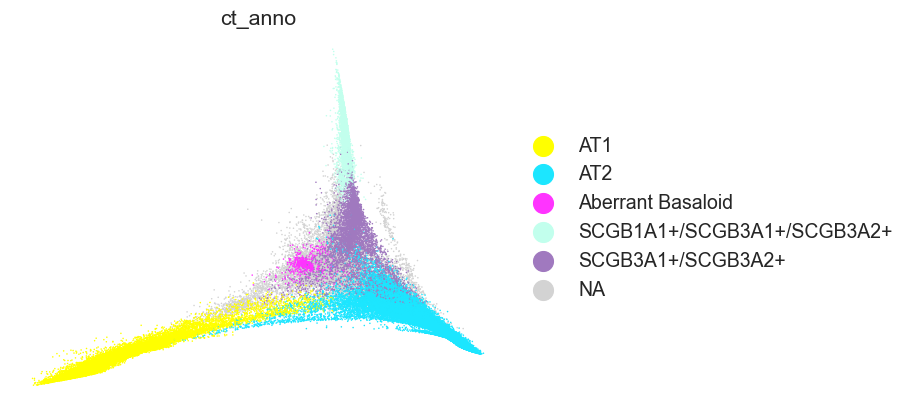

In [8]:
set_vis_default(font = 1.6, circle_marker = 3)
sc.tl.diffmap(adata, n_comps=30, neighbors_key=None, copy=False)
ax = sc.pl.diffmap(
    adata, color=[
        'ct_anno', 
    ], 
    components = ['2,3'], 
    palette = color_dict,
    size=5, frameon=False, show=False,
    cmap = 'viridis', ncols = 1
)
# ax.invert_yaxis()
# ax.invert_xaxis()
plt.show()
plt.close()



In [63]:
import itertools
from seaborn._statistics import ECDF, Histogram, KDE
import matplotlib.contour as mcontour
from matplotlib import colors
from seaborn._statistics import ECDF, Histogram, KDE
import matplotlib.contour as mcontour
from matplotlib import colors
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap


adata_vis = adata[diffmap_index].copy()
embedding = adata_vis.obsm['X_diffmap'][:, [1,2]].copy()
anchor_df = pd.DataFrame(data = embedding, columns = ['emb_X', 'emb_Y'], index = adata_vis.obs.index) 



anchor_df['Group1'] = adata_vis.obs['ct_anno'].tolist()

groups1 = ['SCGB1A1+/SCGB3A1+/SCGB3A2+', 'SCGB3A1+/SCGB3A2+', 'AT2', 'AT1', 'Aberrant Basaloid']
print(groups1)
color_dict = {key: val for key, val in color_dict_all.items() if key in groups1}


set_vis_default(font = 3)
fig, axs = plt.subplots(1, 1, figsize=(12, 10), dpi = 600)


markers = ["o", "v", "*", "s", '+', "1", "p", "x", "D", "d", "|", "_"]


handles = []
labels = []
  
for i, group1 in enumerate(groups1):
    print(group1)
    anchor_df_sub = anchor_df
    size = 3 #size_dict[group2]

    marker = 'o' #marker_dict[group2]
    if group1 is np.nan:
        color = '#E7E6E6'
        group_data = anchor_df_sub[[_ is np.nan for _ in anchor_df_sub['Group1']]]
    else:
        color = color_dict[group1]
        group_data = anchor_df_sub[(anchor_df_sub['Group1'] == group1)]

    axs.scatter(
        group_data['emb_X'], group_data['emb_Y'], 
        color=color, marker = marker, s = size, alpha = 1.,
        edgecolors = 'black', linewidths = .0,
    )


axs.grid(True)

# axs.set_xticks([])
# ax.xaxis.grid(True)
for tick in axs.xaxis.get_major_ticks():
    tick.tick1line.set_visible(False)
    tick.tick2line.set_visible(False)
    tick.label1.set_visible(False)
    tick.label2.set_visible(False)

axs.set_yticks([])
axs.set_xlabel('DC2', fontsize = 35)
axs.set_ylabel('DC3', fontsize = 35)

axs.spines['right'].set_visible(False)
axs.spines['top'].set_visible(False)
for spine in ['left', 'bottom']:
    axs.spines[spine].set_color('black')        
    axs.spines[spine].set_linewidth(3)

from matplotlib.patches import Patch
legend_handles = [Patch(facecolor=color) for key, color in color_dict.items()]
legend_handles = legend_handles #+ [Patch(facecolor='#E7E6E6')]
# legend_handles = [plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=color, markersize=10) for color in color_dict.values()]
legend_labels = [key for key, color in color_dict.items()] #+ ['Uncertain']

plt.legend(
    legend_handles, legend_labels, 
    title='Cell types', bbox_to_anchor=(1.55, 1), 
    bbox_transform=plt.gcf().transFigure, loc='upper right'
)

# plt.savefig(f'./save_figs/sc_epi_zoomin.png', format='png', dpi = 200, bbox_inches='tight',pad_inches=.2)
plt.show()
plt.close()

['SCGB1A1+/SCGB3A1+/SCGB3A2+', 'SCGB3A1+/SCGB3A2+', 'AT2', 'AT1', 'Aberrant Basaloid']
SCGB1A1+/SCGB3A1+/SCGB3A2+
SCGB3A1+/SCGB3A2+
AT2
AT1
Aberrant Basaloid


# spatial data mapped

Please run ./Fig2_sp_map_to_sc_Epi_src/transformer_map_to_atlas.sh first 

Here, UGE_atlas_sub.h5ad is UGE atlas used to be mapped by ST data. It mainly contain cell type AT1, AT2, Aberrant Basaloid, SCGB3A1+/SCGB3A2+, SCGB1A1+/SCGB3A1+/SCGB3A2+, Basal

UGE_sp_sub.h5ad is UGE of ST data containing cell type AT1, AT2, Aberrant Basaloid, SCGB3A1+/SCGB3A2+, Basal from disease slices.

In [26]:
base_path = '/import/home2/xwanaf/Img2Expr/data/Reproducibility_data/PF'
file_path = Path(base_path) / 'sp_map_to_sc_Epi'


file_name = 'UGE_atlas_sub.h5ad'
adata_sc_mapped = sc.read(file_path / file_name)


file_name = 'UGE_sp_sub.h5ad'
adata_inte_epi = sc.read(file_path / file_name)
adata_inte_epi

/home/xwanaf/.conda/envs/py10/lib/python3.10/site-packages/anndata/_core/anndata.py:1756: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


AnnData object with n_obs × n_vars = 128353 × 1741
    obs: 'sample', 'patient', 'cell_id', 'sample_type', 'sample_affect', 'disease_status', 'percent_pathology', 'tma', 'run', 'final_CT', 'final_lineage', 'CNiche', 'TNiche', 'lumen_id', 'lumen_rank', 'x_centroid', 'y_centroid', 'adj_x_centroid', 'adj_y_centroid', 'super_adj_x_centroid', 'super_adj_y_centroid', 'nCount_RNA', 'nFeature_RNA', 'perc_negcontrolprobe', 'perc_negcontrolcodeword', 'perc_unassigned', 'perc_negcontrolorunassigned', 'n_genes', 'pred_atlas', 'predict_mapped_ct_anno_prob', 'Slides'

In [27]:
adata_inte_epi.obs.index = [f'{i}_{j}' for i,j in zip(adata_inte_epi.obs.index, adata_inte_epi.obs['sample'])]



In [71]:
mapping_results_path = '/import/home2/xwanaf/Img2Expr/data/Reproducibility_data/PF/sp_map_to_sc_Epi/results'
mapping_results_path = Path(mapping_results_path)
os.listdir(mapping_results_path)

['pcs.npy',
 'knnpickle_file',
 'adata_all_distances.npz',
 'adata_all_connectivities.npz',
 'transformer_map_to_atlas_log.log',
 'atlas_pcs.npy',
 'neigh_dist_atlas.npy',
 'adata_all.h5ad',
 'neigh_ind.npy',
 'neigh_dist.npy',
 'neigh_ind_atlas.npy']

In [82]:
import numpy as np
from scipy.sparse import coo_matrix, csr_matrix
from scipy.sparse import save_npz, load_npz


sp_cell_num = adata_inte_epi.shape[0]
connectivities = load_npz(mapping_results_path / 'adata_all_connectivities.npz')
connectivities = connectivities[-sp_cell_num:, :-sp_cell_num]
X_diffmap = adata[diffmap_index].obsm['X_diffmap']
row_sums = connectivities.sum(axis=1).A1
row_sums[row_sums == 0] = 1
connectivities_ = connectivities.multiply(1 / row_sums[:, np.newaxis])


connectivities_ = connectivities_.tocsr()
sl_sc_index = [_ is not np.nan for _ in adata[diffmap_index].obs['ct_anno']]
index_ = adata_sc_mapped.obs.index.isin(adata[diffmap_index][sl_sc_index].obs.index)
X_diffmap_sp = connectivities_[:, index_].dot(X_diffmap[sl_sc_index])

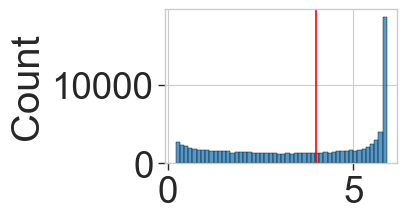

In [84]:
connectivities_sub = connectivities[:, index_]
arr = connectivities_sub.sum(1).A.squeeze()
fig, axs = plt.subplots(1, 1, figsize=(3, 2), gridspec_kw={'wspace': .5, 'hspace': 0.2})
sns.histplot(arr[arr > .2], bins = 50)
axs.axvline(x = 4., color = 'red')
plt.show()
plt.close()


In [85]:
## select sp index that mapped very sure
connectivities_sub = connectivities[:, index_]
arr = connectivities_sub.sum(1).A.squeeze()
index_certain = arr > 4

adata_inte_epi[index_certain].obs['pred_atlas'].value_counts()

pred_atlas
AT2                  26108
SCGB3A1+/SCGB3A2+    18394
AT1                   2575
Aberrant Basaloid      822
Basal                    4
Name: count, dtype: int64

In [86]:
adata_mapped_sp = adata_inte_epi[index_certain].copy()

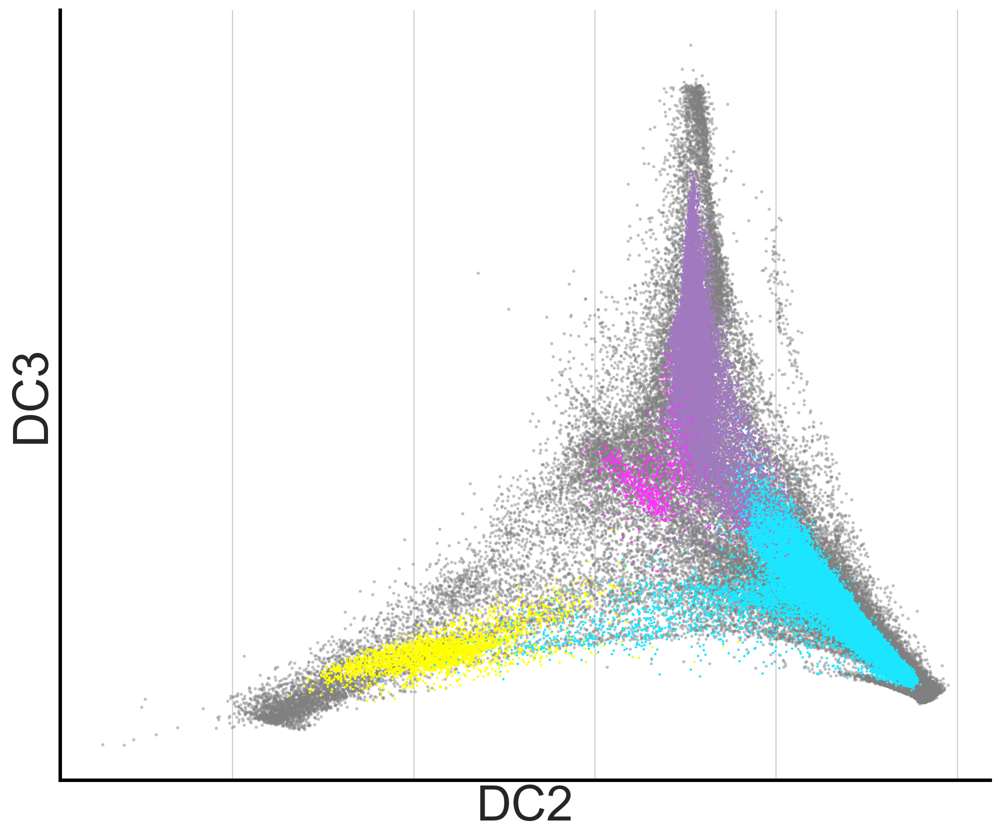

In [88]:
import itertools
from seaborn._statistics import ECDF, Histogram, KDE
import matplotlib.contour as mcontour
from matplotlib import colors
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import matplotlib.colors as mcolors

# ==========================================================================================

adata_vis = adata[diffmap_index].copy()

embedding = adata_vis.obsm['X_diffmap'][:, [1,2]].copy()
anchor_df_sc = pd.DataFrame(data = embedding, columns = ['emb_X', 'emb_Y'], index = adata_vis.obs.index) 


X_diffmap_vis = X_diffmap_sp[index_certain, :][:, [1,2]]
anchor_df = pd.DataFrame(data = X_diffmap_vis, columns = ['emb_X', 'emb_Y'], index = adata_mapped_sp.obs.index) 

colors = adata_mapped_sp.obs['pred_atlas'].map(color_dict_all).values

set_vis_default(font = 3)
fig, axs = plt.subplots(1, 1, figsize=(12, 10), dpi = 200)
# colors = plt.cm.tab20(np.linspace(0, 1, len(groups1)))
markers = ["o", "v", "*", "s", '+', "1", "p", "x", "D", "d", "|", "_"]


handles = []
labels = []
  
    
axs.scatter(
    anchor_df_sc['emb_X'], anchor_df_sc['emb_Y'], 
    color='gray', marker = 'o', s = 5, alpha = .5,
    edgecolors = None, linewidths = .0,
)
axs.scatter(
    anchor_df['emb_X'], anchor_df['emb_Y'], 
    c=colors, marker = 'o', s = 3., alpha = 1.,
    edgecolors = None, linewidths = .0,
)


axs.grid(True)

# axs.set_xticks([])
# ax.xaxis.grid(True)
for tick in axs.xaxis.get_major_ticks():
    tick.tick1line.set_visible(False)
    tick.tick2line.set_visible(False)
    tick.label1.set_visible(False)
    tick.label2.set_visible(False)

axs.set_yticks([])

axs.set_xlabel('DC2', fontsize = 35)
axs.set_ylabel('DC3', fontsize = 35)

axs.spines['right'].set_visible(False)
axs.spines['top'].set_visible(False)
for spine in ['left', 'bottom']:
    axs.spines[spine].set_color('black')        
    axs.spines[spine].set_linewidth(2.5)

# plt.savefig(f'./save_figs/sc_epi_zoomin_sp_mapped.png', format='png', dpi = 200, bbox_inches='tight',pad_inches=.2)
plt.show()
plt.close()


# Assign pseudo time from AT1 to Aberrant Basaloid

In [95]:
save_path = '/import/home2/xwanaf/Img2Expr/data/Reproducibility_data/PF/selected_index'
save_path = Path(save_path)
index_AT1_to_AB = np.load(save_path / 'diffmap_index_AT1_to_AB.npy', allow_pickle=True)

In [96]:
adata_pt = adata[index_AT1_to_AB]

In [97]:
adata_pt

View of AnnData object with n_obs × n_vars = 20830 × 1741
    obs: 'cell_type', 'cell_id', 'dataset_idx', 'dataset_cell_id', 'ann_finest_level', 'dataset', 'ann_level_1', 'disease', 'original_ann_nonharmonized', 'leiden_2p0', 'leiden_2p5', 'leiden_1p5', 'leiden_0p5', 'leiden_1p0', 'leiden_0p5_ct_v0', 'leiden_1p0_ct_v0', 'leiden_2p5_ct_v0', 'tmp', 'leiden_2p5_epi_v1', 'leiden_2p5_epi', 'leiden_2p5_epi_v2', 'leiden_2p5_epi_v3', 'leiden_2p5_epi_v7', 'leiden_2p5_epi_v4', 'leiden_1p_fibro_v1', 'ct_anno'
    uns: 'ann_finest_level_colors', 'dataset_colors', 'leiden_2p0_colors', 'leiden_2p5_colors', 'leiden_2p5_ct_v0_colors', 'leiden_2p5_epi_v1_colors', 'neighbors', 'pca', 'umap', 'diffmap_evals', 'ct_anno_colors'
    obsm: 'X_pca', 'X_umap', 'X_diffmap'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'

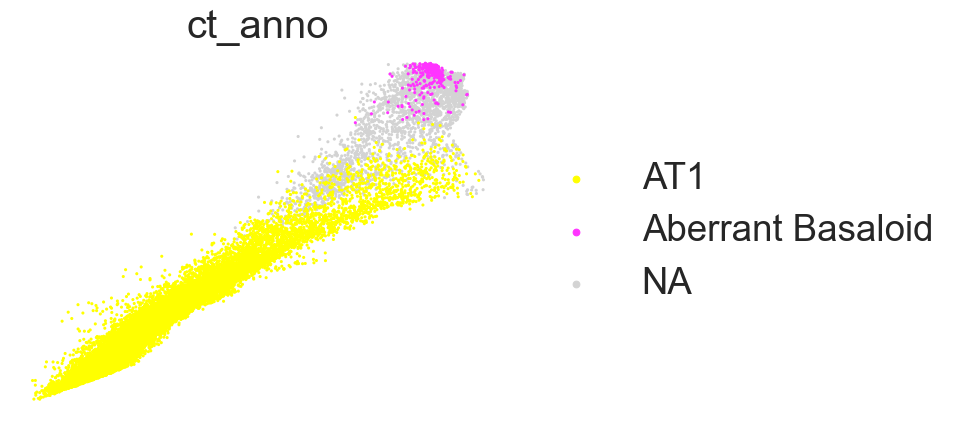

In [99]:
sc.pl.diffmap(
    adata_pt, color=[
        'ct_anno', 
    ], 
    components = ['2,3'], 
    size=20, frameon=False, show=False,
    cmap = 'Spectral', ncols = 3
)


plt.show()
plt.close()


In [102]:
import sys
from velocity_pseudotime import *
from get_connectivities import *

In [103]:
emb_key = 'X_diffmap'

root_cell_name = adata_pt.obs.index[np.argmin(adata_pt.obsm[emb_key][:, 2])] # start AT1
print(adata_pt.obs.index.tolist().index(root_cell_name))


20577


In [104]:
vpt = velocity_pseudotime(adata_pt, root_key = 20577, use_velocity_graph = False, return_model = True)

/import/home/xwanaf/bio/scGPT-dev-temp/Atlas_integration/Reproducibility/PF/velocity_pseudotime.py:36: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
/import/home/xwanaf/bio/scGPT-dev-temp/Atlas_integration/Reproducibility/PF/velocity_pseudotime.py:36: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
/import/home/xwanaf/bio/scGPT-dev-temp/Atlas_integration/Reproducibility/PF/velocity_pseudotime.py:36: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
/import/home/xwanaf/bio/scGPT-dev-temp/Atlas_integration/Reproducibility/PF/velocity_pseudotime.py:36: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
/import/home/xwanaf/bio/scGPT-dev-temp/Atlas_integration/Reproducibility/PF/velocity_pseudotime.py:36: ImplicitModificationWarni

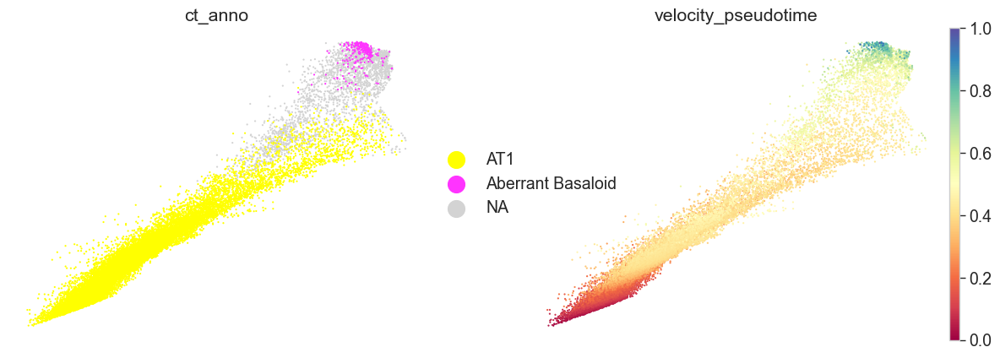

In [106]:
set_vis_default(font = 1.6, circle_marker = 3)
# sc.tl.diffmap(atlas_adata, n_comps=30, neighbors_key=None, copy=False)
sc.pl.diffmap(
    adata_pt,
#     adata2[adata2.obs['velocity_pseudotime'] > .2],
    color=[
        'ct_anno', 'velocity_pseudotime'
    ], 
    components = ['2,3'], 
    size=10, frameon=False, show=True,
#     vmin = 0.25, vmax = np.quantile()
    cmap = 'Spectral', ncols = 3
)


{'AT1': '#ffff00', 'AT2': '#1ce6ff', 'Aberrant Basaloid': '#ff34ff', 'SCGB1A1+/SCGB3A1+/SCGB3A2+': '#c2ffed', 'SCGB3A1+/SCGB3A2+': '#a079bf'}


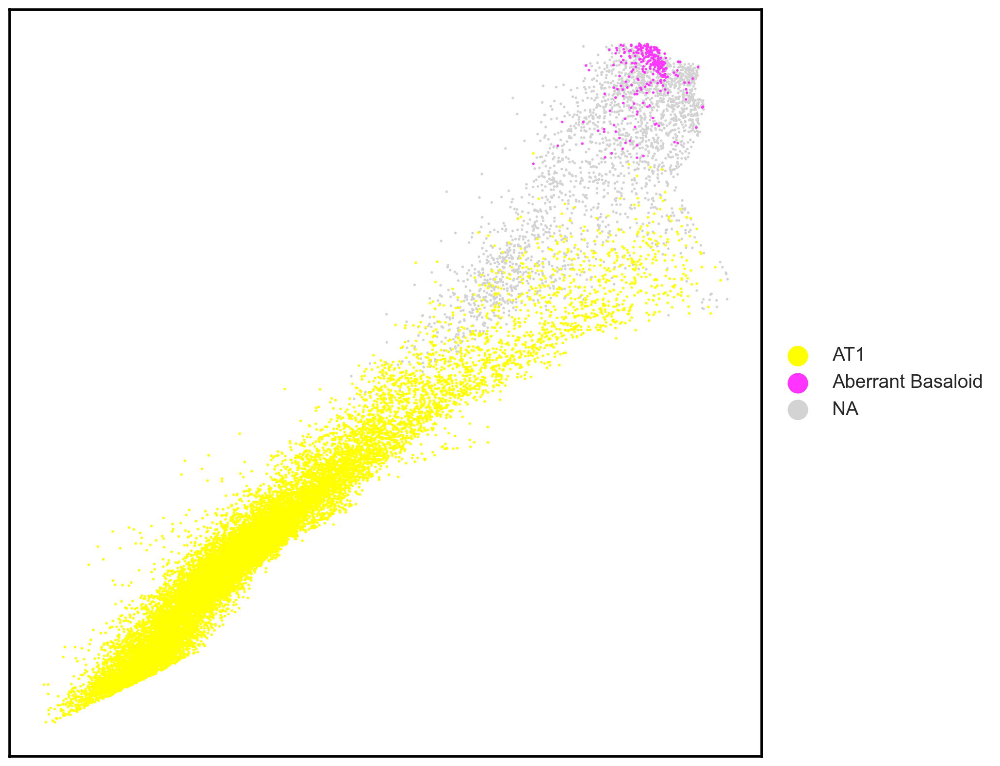

In [107]:
set_vis_default(font = 1.6, circle_marker = 3)
fig, axs = plt.subplots(1, 1, figsize=(10, 10), gridspec_kw={'wspace': .5, 'hspace': 0.2}, dpi = 200)

# sc.tl.diffmap(atlas_adata, n_comps=30, neighbors_key=None, copy=False)
print(color_dict)
sc.pl.diffmap(
    adata_pt,
    color=[
        'ct_anno'
    ], 
    components = ['2,3'], 
    size=15, frameon=True, show=False,
#     vmin = .26, vmax = np.quantile(adata_pt.obs['velocity_pseudotime'], .99),
    cmap = 'Spectral', ncols = 3, palette = color_dict,
    ax = axs
)
for spine in ['left', 'right', 'top', 'bottom']:
    axs.spines[spine].set_color('black')        
    axs.spines[spine].set_linewidth(2)
axs.set_title('')
axs.set_ylabel('')
axs.set_xlabel('')
# plt.savefig(f'./save_figs/sc_path1_ct.png', format='png', dpi = 200, bbox_inches='tight',pad_inches=.1)
plt.show()
plt.close()

/tmp/ipykernel_3451814/1168229554.py:29: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('Spectral').reversed()
/tmp/ipykernel_3451814/1168229554.py:45: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  index = (adata_vis.obs['velocity_pseudotime'][reorder_index] < .5)
/tmp/ipykernel_3451814/1168229554.py:53: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  index = (adata_vis.obs['velocity_pseudotime'][reorder_index] >= .5)


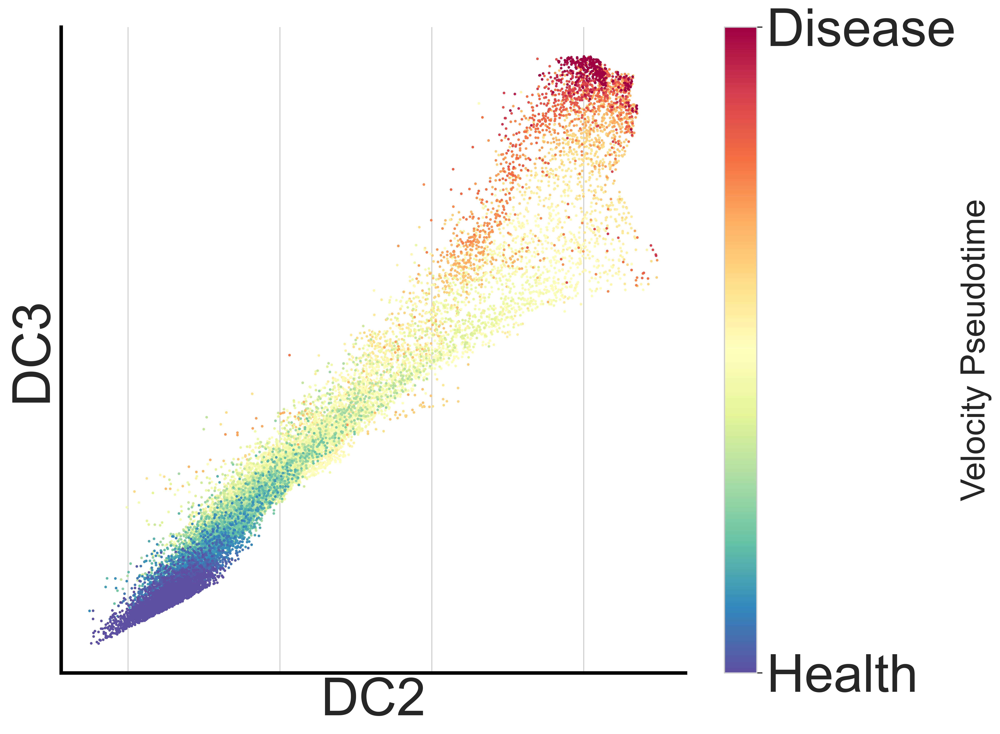

In [109]:
import itertools
from seaborn._statistics import ECDF, Histogram, KDE
import matplotlib.contour as mcontour
from matplotlib import colors
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import matplotlib.cm as cm



# ==========================================================================================

adata_vis = adata_pt.copy()
adata_vis.obs['velocity_pseudotime'] = adata_vis.obs['velocity_pseudotime']
float_values = adata_vis.obs['velocity_pseudotime'].to_numpy()
vmin, vmax = .1, np.quantile(float_values, .99)
index = (float_values >= vmin) & (float_values <= vmax)



embedding = adata_vis.obsm['X_diffmap'][:, [1,2]].copy()
anchor_df = pd.DataFrame(data = embedding, columns = ['emb_X', 'emb_Y'], index = adata_vis.obs.index) 
# anchor_df_sc = anchor_df_sc[anchor_df_sc['emb_X'] > -0.009]
anchor_df['velocity_pseudotime'] = adata_vis.obs['velocity_pseudotime']


float_values = anchor_df['velocity_pseudotime'].to_numpy()
cmap = cm.get_cmap('Spectral').reversed()
# vmin, vmax = np.quantile(float_values, .01), .75
norm = plt.Normalize(vmin=vmin, vmax=vmax)
colors = cmap(norm(float_values))


set_vis_default(font = 3)
fig, axs = plt.subplots(1, 1, figsize=(12, 10), dpi = 600)
# colors = plt.cm.tab20(np.linspace(0, 1, len(groups1)))
markers = ["o", "v", "*", "s", '+', "1", "p", "x", "D", "d", "|", "_"]


handles = []
labels = []
  
reorder_index = np.argsort(adata_vis.obs['velocity_pseudotime'])[::-1]
index = (adata_vis.obs['velocity_pseudotime'][reorder_index] < .5)
axs.scatter(
    anchor_df.iloc[reorder_index][index]['emb_X'], anchor_df.iloc[reorder_index][index]['emb_Y'], 
    color=colors[reorder_index][index], marker = 'o', s = 5, alpha = 1.,
    edgecolors = None, linewidths = .0,
)

reorder_index = np.argsort(adata_vis.obs['velocity_pseudotime'])#[::-1]
index = (adata_vis.obs['velocity_pseudotime'][reorder_index] >= .5)
axs.scatter(
    anchor_df.iloc[reorder_index][index]['emb_X'], anchor_df.iloc[reorder_index][index]['emb_Y'], 
    color=colors[reorder_index][index], marker = 'o', s = 5, alpha = 1.,
    edgecolors = None, linewidths = .0,
)



axs.grid(True)

# axs.set_xticks([])
# ax.xaxis.grid(True)
for tick in axs.xaxis.get_major_ticks():
    tick.tick1line.set_visible(False)
    tick.tick2line.set_visible(False)
    tick.label1.set_visible(False)
    tick.label2.set_visible(False)

axs.set_yticks([])

axs.set_xlabel('DC2', fontsize = 45)
axs.set_ylabel('DC3', fontsize = 45)

axs.spines['right'].set_visible(False)
axs.spines['top'].set_visible(False)
for spine in ['left', 'bottom']:
    axs.spines[spine].set_color('black')        
    axs.spines[spine].set_linewidth(3)

# Add a colorbar
cbar = fig.colorbar(cm.ScalarMappable(norm=norm, cmap=cmap), ax=axs)
cbar.set_label('Velocity Pseudotime')  # Label for the colorbar
cbar.set_ticks([vmin, vmax])  # Set ticks if desired
cbar.ax.set_yticklabels(['Health', 'Disease'], fontsize = 45)  # Custom tick labels

# plt.savefig(f'./save_figs/sc_path1_pseudotime_startAT2_rmAT2.png', format='png', dpi = 200, bbox_inches='tight',pad_inches=1)
plt.show()
plt.close()

# Transfer pseudo time to spatial


In [116]:
mapping_results_path = '/import/home2/xwanaf/Img2Expr/data/Reproducibility_data/PF/sp_map_to_sc_Epi/results_NN300'
mapping_results_path = Path(mapping_results_path)
os.listdir(mapping_results_path)

['pcs.npy',
 'knnpickle_file',
 'adata_all_distances.npz',
 'adata_all_connectivities.npz',
 'transformer_map_to_atlas_log.log',
 'atlas_pcs.npy',
 'neigh_dist_atlas.npy',
 'adata_all.h5ad',
 'neigh_ind.npy',
 'neigh_dist.npy',
 'neigh_ind_atlas.npy']

In [117]:
import numpy as np
from scipy.sparse import coo_matrix, csr_matrix
from scipy.sparse import save_npz, load_npz


sp_cell_num = adata_inte_epi.shape[0]
connectivities = load_npz(mapping_results_path / 'adata_all_connectivities.npz')
connectivities = connectivities[-sp_cell_num:, :-sp_cell_num]

row_sums = connectivities.sum(axis=1).A1
row_sums[row_sums == 0] = 1
connectivities_ = connectivities.multiply(1 / row_sums[:, np.newaxis])
connectivities_ = connectivities_.tocsr()

###### change backgroud sc atlas 
X_diffmap = adata_pt.obsm['X_diffmap']
index_ = adata_sc_mapped.obs.index.isin(adata_pt.obs.index)
X_diffmap_sp = connectivities_[:, index_].dot(X_diffmap)

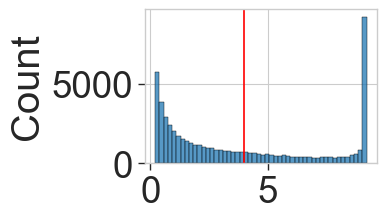

In [120]:
connectivities_sub = connectivities[:, index_]
arr = connectivities_sub.sum(1).A.squeeze()
fig, axs = plt.subplots(1, 1, figsize=(3, 2), gridspec_kw={'wspace': .5, 'hspace': 0.2})
sns.histplot(arr[arr > .2], bins = 50)
axs.axvline(x = 4., color = 'red')
plt.show()
plt.close()


In [121]:
## select sp index that mapped very sure
connectivities_sub = connectivities[:, index_]
arr = connectivities_sub.sum(1).A.squeeze()
index_certain = arr > 4

adata_inte_epi[index_certain].obs['pred_atlas'].value_counts()

pred_atlas
AT1                  13244
Aberrant Basaloid     8001
AT2                   1406
SCGB3A1+/SCGB3A2+      167
Basal                   36
Name: count, dtype: int64

In [122]:
adata_mapped_sp = adata_inte_epi[index_certain].copy()

## transfer time here

In [123]:
# connectivities_ = connectivities_sub / connectivities_sub.sum(1)
row_sums = connectivities_sub.sum(axis=1).A1  # Convert to a 1D array
row_sums[row_sums == 0] = 1
connectivities_ = connectivities_sub.multiply(1 / row_sums[:, np.newaxis])


adata_mapped_sp.obs['time'] = connectivities_.dot(adata_pt.obs['velocity_pseudotime'])[index_certain]


In [124]:
adata_mapped_sp.obs['time'].max(), adata_mapped_sp.obs['time'].min()

(np.float64(0.8441993269529795), np.float64(0.05689997878822942))

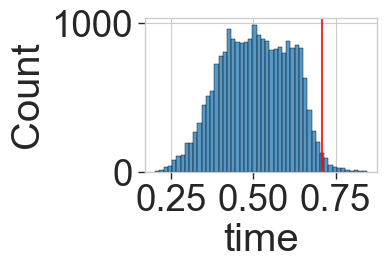

In [125]:
arr = adata_mapped_sp.obs['time']
fig, axs = plt.subplots(1, 1, figsize=(3, 2), gridspec_kw={'wspace': .5, 'hspace': 0.2})
sns.histplot(arr[arr > .2], bins = 50)
axs.axvline(x = np.quantile(float_values, .99), color = 'red')
plt.show()
plt.close()


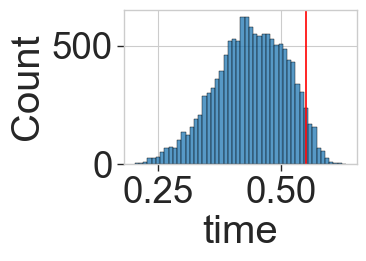

In [130]:
arr = adata_mapped_sp.obs['time']
arr = adata_mapped_sp[adata_mapped_sp.obs['pred_atlas'] == 'AT1'].obs['time']
fig, axs = plt.subplots(1, 1, figsize=(3, 2), gridspec_kw={'wspace': .5, 'hspace': 0.2})
sns.histplot(arr[arr > .2], bins = 50)
axs.axvline(x = .55, color = 'red')
plt.show()
plt.close()


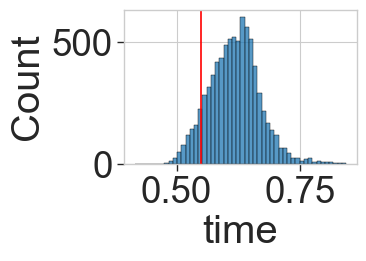

In [131]:
arr = adata_mapped_sp.obs['time']
arr = adata_mapped_sp[adata_mapped_sp.obs['pred_atlas'] == 'Aberrant Basaloid'].obs['time']
fig, axs = plt.subplots(1, 1, figsize=(3, 2), gridspec_kw={'wspace': .5, 'hspace': 0.2})
sns.histplot(arr[arr > .2], bins = 50)
axs.axvline(x = .55, color = 'red')
plt.show()
plt.close()


In [139]:
adata_mapped_sp.obsm['X_diffmap'] = X_diffmap_sp[index_certain, :]

In [138]:
adata_mapped_sp

AnnData object with n_obs × n_vars = 22854 × 1741
    obs: 'sample', 'patient', 'cell_id', 'sample_type', 'sample_affect', 'disease_status', 'percent_pathology', 'tma', 'run', 'final_CT', 'final_lineage', 'CNiche', 'TNiche', 'lumen_id', 'lumen_rank', 'x_centroid', 'y_centroid', 'adj_x_centroid', 'adj_y_centroid', 'super_adj_x_centroid', 'super_adj_y_centroid', 'nCount_RNA', 'nFeature_RNA', 'perc_negcontrolprobe', 'perc_negcontrolcodeword', 'perc_unassigned', 'perc_negcontrolorunassigned', 'n_genes', 'pred_atlas', 'predict_mapped_ct_anno_prob', 'Slides', 'time'

In [140]:
base_path = '/import/home2/xwanaf/Img2Expr/data/Reproducibility_data/PF'
file_path = Path(base_path) / 'sp_map_to_sc_Epi'

file_name = 'UGE_sp_added_time.h5ad'
# adata_mapped_sp.write(file_path / file_name)

/tmp/ipykernel_3451814/3500051691.py:25: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('Spectral').reversed()


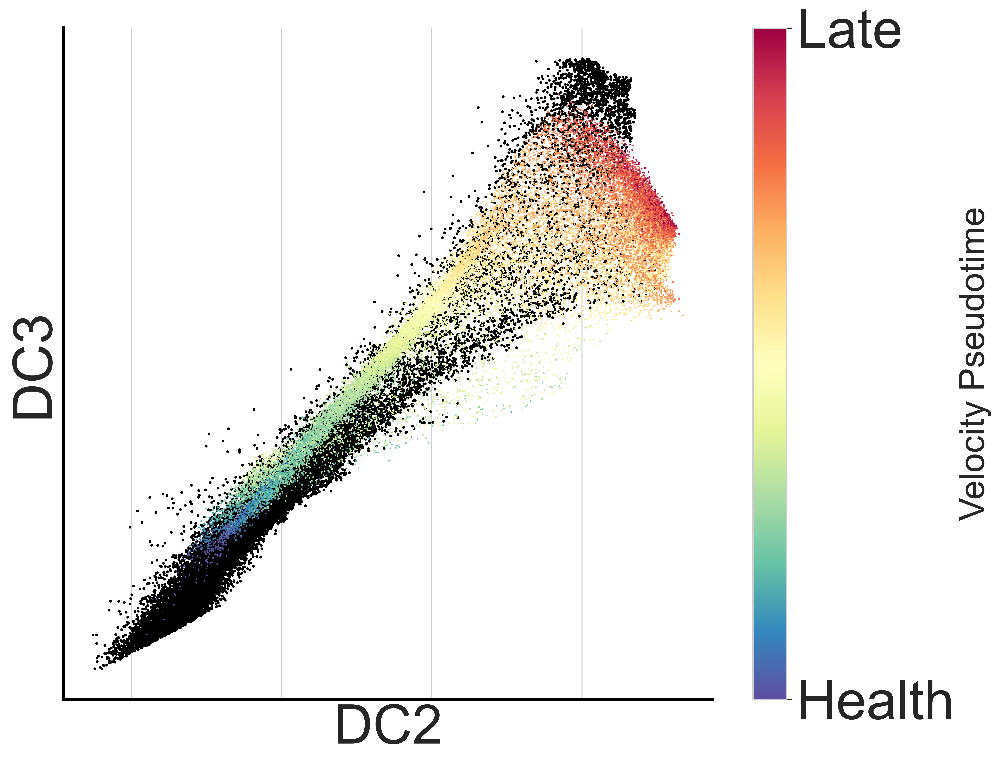

In [134]:
import itertools
from seaborn._statistics import ECDF, Histogram, KDE
import matplotlib.contour as mcontour
from matplotlib import colors
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap




# ==========================================================================================

adata_vis = adata_pt.copy()

embedding = adata_vis.obsm['X_diffmap'][:, [1,2]].copy()
anchor_df_sc = pd.DataFrame(data = embedding, columns = ['emb_X', 'emb_Y'], index = adata_vis.obs.index) 
# anchor_df_sc = anchor_df_sc[anchor_df_sc['emb_X'] > -0.009]

X_diffmap_vis = X_diffmap_sp[index_certain, :][:, [1,2]]
anchor_df = pd.DataFrame(data = X_diffmap_vis, columns = ['emb_X', 'emb_Y'], index = adata_mapped_sp.obs.index) 


float_values = adata_mapped_sp.obs['time'].to_numpy()
cmap = cm.get_cmap('Spectral').reversed()
vmin, vmax = .25, np.quantile(float_values, .99)
norm = plt.Normalize(vmin=vmin, vmax=vmax)
colors = cmap(norm(float_values))


set_vis_default(font = 3)
fig, axs = plt.subplots(1, 1, figsize=(12, 10), dpi = 600)
# colors = plt.cm.tab20(np.linspace(0, 1, len(groups1)))
markers = ["o", "v", "*", "s", '+', "1", "p", "x", "D", "d", "|", "_"]


handles = []
labels = []
  
    
axs.scatter(
    anchor_df_sc['emb_X'], anchor_df_sc['emb_Y'], 
    color='black', marker = 'o', s = 5, alpha = 1.,
    edgecolors = None, linewidths = .0,
)
axs.scatter(
    anchor_df['emb_X'], anchor_df['emb_Y'], 
    color=colors, marker = 'o', s = 2, alpha = 1.,
    edgecolors = None, linewidths = .0,
)

axs.grid(True)

# axs.set_xticks([])
# ax.xaxis.grid(True)
for tick in axs.xaxis.get_major_ticks():
    tick.tick1line.set_visible(False)
    tick.tick2line.set_visible(False)
    tick.label1.set_visible(False)
    tick.label2.set_visible(False)

axs.set_yticks([])

axs.set_xlabel('DC2', fontsize = 45)
axs.set_ylabel('DC3', fontsize = 45)

axs.spines['right'].set_visible(False)
axs.spines['top'].set_visible(False)
for spine in ['left', 'bottom']:
    axs.spines[spine].set_color('black')        
    axs.spines[spine].set_linewidth(3)

# Add a colorbar
cbar = fig.colorbar(cm.ScalarMappable(norm=norm, cmap=cmap), ax=axs)
cbar.set_label('Velocity Pseudotime')  # Label for the colorbar
vmin, vmax = .25, np.quantile(float_values, .99)
cbar.set_ticks([vmin, vmax])  # Set ticks if desired
cbar.ax.set_yticklabels(['Health', 'Late'], fontsize = 45)  # Custom tick labels

# plt.savefig(f'./save_figs/sp_path1_pseudotime_startAT2_rmAT2.png', format='png', dpi = 200, bbox_inches='tight',pad_inches=1)
plt.show()
plt.close()